# 实验七：图注意力网络与 Cora 论文分类

一篇论文的词特征可以帮助判断研究方向。与它相连的论文，能否提供额外线索？
如果邻居的作用不同，我们能否学习怎样分配它们的权重？

本次完成固定引用网络上的七分类：**认识数据 → 小图注意力 → GAT → 三组对照 → 局部分析 → 最终评价**。
每一阶段先作预测，再运行和检查。允许使用 AI，但请核验关键建议，区分观察到的结果与对原因的猜测。

必做 Q1–Q6；课时紧时 B 组可使用教师同配置参考结果。选做拓展最多一项。


**教师参考版。** 本版提供完整实现、解释和实际运行输出。学生版的 Q1、Q2、Q3a、Q3b 为待补全位置；
参考成绩只描述当前配置，不能作为学生必须达到的阈值。请同时阅读本目录 README 中的验证与运行说明。


## 0 · 环境、文件与约定

沿用 ai-lab 环境，使用 PyTorch、NumPy、Matplotlib 与 Jupyter。无需安装 PyG、DGL 或 labml，无需下载数据。
将 notebook、lab_utils.py 与 cora 文件夹放在同一目录，从该目录启动。

| 项目 | 约定 |
| --- | --- |
| 任务 | 传导式半监督节点分类，7 类 |
| 划分 | 每类 20 个训练标签，共 140；验证 500；测试 2,068；划分种子 42 |
| 输入 | 全部节点的词特征与引用关系，训练时仅使用训练标签计算损失 |
| 图 | 引用关系双向化、去重、添加自环；edge_index 第 0 行接收，第 1 行发送 |
| 模型 | 第一层 8 头×8 维，拼接为 64 维；ELU；第二层输出 7 个 logits |
| 训练 | 全图训练，300 轮，每轮一次更新；Adam，lr=0.005，weight_decay=0.0005 |
| 正则 | 特征与注意力 dropout 均为 0.6；分析时关闭 dropout |
| 选模 | 验证准确率最高，持平时验证损失最低，再持平选较早轮次 |
| 设备 | 默认 CPU，最多 4 个线程；CUDA 可选，其他设备未验证 |

所有对照使用相同预算。环境变量 LAB7_EPOCHS 只用于开发时缩短运行；改变后必须记录实际轮数。
本实验是课堂自定义划分，不与不同划分下的论文成绩直接比较。
输出文件写入本目录“输出”文件夹，首次运行前不需要创建。


In [1]:
import os
import platform
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from IPython import get_ipython
from IPython.display import Markdown, display

assert Path("lab_utils.py").exists(), "请在实验七目录运行 notebook，并保留 cora 文件夹。"
from lab_utils import (
    GROUPS, SHORT_NAMES, read_raw_cora, normalize_features, stratified_split,
    save_split, edge_softmax, uniform_attention, sum_messages, dense_attention,
    self_edges, edges_for_group, seed_everything, snapshot, parameter_counts,
    fit_model, print_comparison, plot_history, select_validation_nodes,
    plot_attention_neighborhood, edge_sensitivity, classification_metrics,
    plot_confusions, save_run_report,
)

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(min(4, os.cpu_count() or 1))
SEED, SPLIT_SEED = 42, 42
EPOCHS = int(os.environ.get("LAB7_EPOCHS", "300"))
DEVICE = torch.device(os.environ.get("LAB7_DEVICE", "cpu"))
assert DEVICE.type in {"cpu", "cuda"}, "本版按边算子以 CPU 为基础；CUDA 可选。"
assert EPOCHS > 0
CONFIG = dict(epochs=EPOCHS, lr=0.005, weight_decay=0.0005,
              hidden=64, heads=8, dropout=0.6, seed=SEED, split_seed=SPLIT_SEED)
ENVIRONMENT = dict(python=sys.version.split()[0], torch=torch.__version__,
                   numpy=np.__version__, device=str(DEVICE), machine=platform.machine(),
                   threads=torch.get_num_threads())
OUTPUT_DIR = Path("输出")
OUTPUT_DIR.mkdir(exist_ok=True)
seed_everything(SEED)
print(ENVIRONMENT)
print(CONFIG)


{'python': '3.12.14', 'torch': '2.14.1', 'numpy': '2.5.3', 'device': 'cpu', 'machine': 'arm64', 'threads': 4}
{'epochs': 300, 'lr': 0.005, 'weight_decay': 0.0005, 'hidden': 64, 'heads': 8, 'dropout': 0.6, 'seed': 42, 'split_seed': 42}


## Q1 · 从论文文件到图

cora.content 每行依次是论文 ID、1,433 个二值词特征、类别；cora.cites 每行是“被引用论文、引用论文”。
文件中的 ID 不连续。节点数组按 content 行顺序排列，必须先建立 ID 到下标的映射。

**完成 encode_cora。** 主实验允许双向交换信息，所以每条引用加入两个方向；用集合去重，再为每个节点添加一个自环。
特征归一化工具已提供，全零行保持为零。

先回答：原始引用有 5,429 行，无向化后是否一定有 10,858 条不同的消息？为什么？
没有训练标签的论文，是否应该从图中删掉？


In [2]:
def encode_cora(contents, citations):
    # 保留 content 文件行顺序；论文 ID 是字符串，不把它直接当张量下标。
    paper_ids = [row[0] for row in contents]
    assert len(paper_ids) == len(set(paper_ids))
    id_to_idx = {paper_id: i for i, paper_id in enumerate(paper_ids)}
    class_names = sorted({row[-1] for row in contents})
    class_to_idx = {name: i for i, name in enumerate(class_names)}
    x = torch.from_numpy(np.asarray([row[1:-1] for row in contents], dtype=np.float32))
    y = torch.tensor([class_to_idx[row[-1]] for row in contents], dtype=torch.long)
    # receiver, sender：任一方向存在引用，双方均可交换消息。
    pairs = set()
    for cited, citing in citations:
        u, v = id_to_idx[cited], id_to_idx[citing]
        pairs.update([(u, v), (v, u)])
    pairs.update((i, i) for i in range(len(paper_ids)))
    edges = torch.tensor(sorted(pairs), dtype=torch.long).T.contiguous()
    return paper_ids, class_names, normalize_features(x), y, edges


In [3]:
contents, citations = read_raw_cora()
paper_ids, class_names, x_cpu, y, edges_cpu = encode_cora(contents, citations)
assert len(paper_ids) == 2708 and x_cpu.shape == (2708, 1433)
assert y.shape == (2708,) and y.dtype == torch.long and len(class_names) == 7
assert x_cpu.dtype == torch.float32 and torch.isfinite(x_cpu).all()
assert edges_cpu.shape == (2, 13264)
pairs = set(map(tuple, edges_cpu.T.tolist()))
assert len(pairs) == edges_cpu.shape[1]
assert all((j, i) in pairs for i, j in pairs)
assert sum(i == j for i, j in pairs) == 2708
row_sums = x_cpu.sum(1)
assert torch.allclose(row_sums[row_sums > 0], torch.ones_like(row_sums[row_sums > 0]))
print("原始引用记录:", len(citations), "含自环的消息条目:", edges_cpu.shape[1])
print("X:", tuple(x_cpu.shape), "y:", tuple(y.shape), "edges:", tuple(edges_cpu.shape))
print("类别顺序:", class_names)
del contents, citations, pairs

split = stratified_split(y, seed=SPLIT_SEED)
train_idx, val_idx, test_idx = split["train"], split["val"], split["test"]
all_indices = torch.cat([train_idx, val_idx, test_idx])
assert all_indices.unique().numel() == len(y) == all_indices.numel()
assert [len(train_idx), len(val_idx), len(test_idx)] == [140, 500, 2068]
assert torch.equal(torch.bincount(y[train_idx]), torch.full((7,), 20))
save_split(split, paper_ids, class_names, OUTPUT_DIR)
print("训练／验证／测试节点数:", {key: len(value) for key, value in split.items()})
print("训练类别数:", torch.bincount(y[train_idx]).tolist())
x, edges = x_cpu.to(DEVICE), edges_cpu.to(DEVICE)


原始引用记录: 5429 含自环的消息条目: 13264
X: (2708, 1433) y: (2708,) edges: (2, 13264)
类别顺序: ['Case_Based', 'Genetic_Algorithms', 'Neural_Networks', 'Probabilistic_Methods', 'Reinforcement_Learning', 'Rule_Learning', 'Theory']


训练／验证／测试节点数: {'train': 140, 'val': 500, 'test': 2068}
训练类别数: [20, 20, 20, 20, 20, 20, 20]


**参考解释**

原始文件包含少量互相引用的记录，双向化后要去重，因此不是简单乘二。
    无向边有 5,278 条，双向消息为 10,556 条，加自环为 13,264 条。类别顺序固定，避免标签编码随进程变化。
    所有节点及其特征、关系都参与前向；只有 140 个训练节点的真实类别参与损失。
    这是在已知图中预测未知标签，并没有验证新图或未来新论文上的泛化。


## Q2 · 在小图上核验注意力

对接收节点 i，先变换特征 z_i，再为允许发送消息的节点 j 打分：

$$e_{ij}=\operatorname{LeakyReLU}(a^\top[z_i\Vert z_j]),\quad
\alpha_{ij}=\frac{\exp(e_{ij})}{\sum_{k\in\mathcal N(i)\cup\{i\}}\exp(e_{ik})},\quad
h'_i=\sum_j\alpha_{ij}z_j.$$

**完成 toy_attention 的掩码、softmax 和加权求和。** 这里只用一个头和一个小图，允许构造稠密矩阵。
图中 0 与 1、2 相连，3 只有自身。每个节点都有自环。

先预测：等权聚合时节点 0 的输出是多少？节点 3 的权重是多少？将非邻居的分数设为 0，能否阻止它参与聚合？


In [4]:
def toy_attention(x, adjacency, weight, attention_vector):
    """小图专用稠密实现；adjacency[i,j] 表示 i 接收 j 的消息。"""
    z = x @ weight
    n = len(x)
    pair_features = torch.cat([
        z[:, None, :].expand(n, n, -1),
        z[None, :, :].expand(n, n, -1),
    ], dim=-1)
    scores = F.leaky_relu(pair_features @ attention_vector, negative_slope=0.2)
    # 非邻居不参与归一化；softmax 沿发送邻居这一维进行。
    masked_scores = scores.masked_fill(~adjacency, -torch.inf)
    alpha = masked_scores.softmax(dim=1)
    output = alpha @ z
    return output, alpha


In [5]:
toy_x = torch.tensor([[1., 0.], [0., 1.], [1., 1.], [2., -1.]])
toy_adj = torch.eye(4, dtype=torch.bool)
toy_adj[0, 1] = toy_adj[1, 0] = True
toy_adj[0, 2] = toy_adj[2, 0] = True
toy_edges = torch.stack(torch.where(toy_adj))
toy_w = torch.eye(2)
toy_a = torch.tensor([0.3, -0.1, 0.2, 0.4])
toy_out, toy_alpha = toy_attention(toy_x, toy_adj, toy_w, toy_a)
print("注意力矩阵（行接收、列发送）:\n", toy_alpha)
print("聚合输出:\n", toy_out)
assert torch.all(toy_alpha[~toy_adj] == 0)
assert torch.allclose(toy_alpha.sum(1), torch.ones(4))
assert toy_alpha[3, 3] == 1 and torch.allclose(toy_out[3], toy_x[3])

uniform_out, _ = toy_attention(toy_x, toy_adj, toy_w, torch.zeros(4))
assert torch.allclose(uniform_out[0], torch.tensor([2/3, 2/3]))
changed_neighbor = toy_x.clone()
changed_neighbor[1] += torch.tensor([0.7, -0.2])
changed_out, _ = toy_attention(changed_neighbor, toy_adj, toy_w, toy_a)
assert not torch.allclose(changed_out[0], toy_out[0])
changed_non_neighbor = toy_x.clone()
changed_non_neighbor[3] += 10
distant_out, _ = toy_attention(changed_non_neighbor, toy_adj, toy_w, toy_a)
assert torch.allclose(distant_out[0], toy_out[0])
print("通过：掩码、归一化、自环、等权均值和局部扰动检查。")


注意力矩阵（行接收、列发送）:
 tensor([[0.2693, 0.3289, 0.4018, 0.0000],
        [0.4502, 0.5498, 0.0000, 0.0000],
        [0.4013, 0.0000, 0.5987, 0.0000],
        [0.0000, 0.0000, 0.0000, 1.0000]])
聚合输出:
 tensor([[ 0.6711,  0.7307],
        [ 0.4502,  0.5498],
        [ 1.0000,  0.5987],
        [ 2.0000, -1.0000]])
通过：掩码、归一化、自环、等权均值和局部扰动检查。


**参考解释**

节点 0 的等权输出为 (2/3,2/3)；节点 3 的自环权重为 1。
    softmax 只沿行内的发送邻居归一化。非邻居分数应被排除，设为 0 仍有 exp(0)=1。
    单层中非邻居不会直接改变该节点输出；两层后两跳范围内的信息可能间接影响它。
    以上求和为 1 的检查适用于 dropout 前，训练时注意力 dropout 后不要求和为 1。


## Q3 · 将计算迁移到完整图

完整图只存储现有的消息条目。receiver 和 sender 都是长度 E 的下标数组。
一层变换后的特征 z 为 (N,H,F)，沿边取值后为 (E,H,F)，注意力为 (E,H)。

**Q3a：** 用接收与发送两段内积计算分数，再使用 edge_softmax 按接收节点、每头归一化。
**Q3b：** 对发送特征加权，通过 sum_messages 聚合到接收节点。
分组运算已提供，请重点说明每个数组的含义。

网络结构、初始化与模式开关已给出。B 固定等权；C 学习打分参数。A 与 B 使用同样的等权模式，只改变输入关系。
第一层拼接 8 个头，第二层只有 1 个输出头。


In [6]:
class GATLayer(nn.Module):
    def __init__(self, in_features, out_features, heads=1, concat=True,
                 attention="learned", dropout=0.6):
        super().__init__()
        assert attention in {"uniform", "learned"}
        self.heads, self.out_features = heads, out_features
        self.concat, self.attention, self.dropout = concat, attention, dropout
        self.linear = nn.Linear(in_features, heads * out_features, bias=False)
        self.attn_receiver = nn.Parameter(torch.empty(heads, out_features))
        self.attn_sender = nn.Parameter(torch.empty(heads, out_features))
        # 所有组均按相同顺序初始化，保证共享特征变换的初值一致。
        nn.init.xavier_uniform_(self.linear.weight, gain=2 ** 0.5)
        nn.init.xavier_uniform_(self.attn_receiver, gain=2 ** 0.5)
        nn.init.xavier_uniform_(self.attn_sender, gain=2 ** 0.5)
        if attention == "uniform":
            self.attn_receiver.requires_grad_(False)
            self.attn_sender.requires_grad_(False)

    def forward(self, x, edges, return_attention=False):
        n = len(x)
        receiver, sender = edges
        z = self.linear(x).reshape(n, self.heads, self.out_features)
        if self.attention == "learned":
            # 分开计算拼接向量的两段内积，避免构造所有节点对。
            scores = (z[receiver] * self.attn_receiver).sum(-1)
            scores = scores + (z[sender] * self.attn_sender).sum(-1)
            scores = F.leaky_relu(scores, negative_slope=0.2)
            alpha = edge_softmax(scores, receiver, n)
        else:
            alpha = uniform_attention(receiver, n, self.heads, x.dtype)
        # 保存的 alpha 是 dropout 前的归一化权重。
        used_alpha = F.dropout(alpha, p=self.dropout, training=self.training)
        messages = used_alpha[..., None] * z[sender]
        aggregated = sum_messages(messages, receiver, n)
        output = aggregated.reshape(n, -1) if self.concat else aggregated.mean(dim=1)
        return (output, alpha) if return_attention else output


class GAT(nn.Module):
    def __init__(self, in_features, n_classes, hidden=64, heads=8,
                 attention="learned", dropout=0.6):
        super().__init__()
        assert hidden % heads == 0
        self.dropout = dropout
        self.layer1 = GATLayer(in_features, hidden // heads, heads, True, attention, dropout)
        self.layer2 = GATLayer(hidden, n_classes, 1, False, attention, dropout)

    def forward(self, x, edges, return_attention=False):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x, alpha1 = self.layer1(x, edges, return_attention=True)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        logits, alpha2 = self.layer2(x, edges, return_attention=True)
        return (logits, [alpha1, alpha2]) if return_attention else logits


def make_model(group, seed=SEED):
    seed_everything(seed)
    mode = "learned" if group == "C" else "uniform"
    return GAT(1433, 7, hidden=CONFIG["hidden"], heads=CONFIG["heads"],
               attention=mode, dropout=CONFIG["dropout"]).to(DEVICE)


In [7]:
# 按边实现应与 Q2 的稠密计算相符。
layer = GATLayer(2, 2, heads=1, concat=False, dropout=0).eval()
with torch.no_grad():
    layer.linear.weight.copy_(toy_w.T)
    layer.attn_receiver.copy_(toy_a[:2][None])
    layer.attn_sender.copy_(toy_a[2:][None])
edge_out, edge_alpha = layer(toy_x, toy_edges, return_attention=True)
assert torch.allclose(edge_out, toy_out, atol=1e-6)
assert torch.allclose(dense_attention(edge_alpha, toy_edges, 4)[..., 0], toy_alpha, atol=1e-6)
print("通过：稠密小图与按边实现一致。")

# 故意关闭 dropout，区分求梯度与更新参数，不影响正式训练初值。
seed_everything(7)
check_model = GAT(1433, 7, dropout=0).to(DEVICE)
optimizer = torch.optim.SGD(check_model.parameters(), lr=0.1)
train_on_device = train_idx.to(DEVICE)
labels_on_device = y[train_idx].to(DEVICE)
before = snapshot(check_model)
optimizer.zero_grad(set_to_none=True)
check_logits = check_model(x, edges)
assert check_logits.shape == (2708, 7)
check_loss = F.cross_entropy(check_logits[train_on_device], labels_on_device)
check_loss.backward()
assert torch.isfinite(check_loss)
assert check_model.layer1.linear.weight.grad.abs().sum() > 0
assert all(torch.equal(before[key], value.cpu()) for key, value in check_model.state_dict().items())
optimizer.step()
assert not torch.equal(before["layer1.linear.weight"], check_model.layer1.linear.weight.detach().cpu())
print("loss:", float(check_loss.detach()), "通过：backward 求梯度，step 更新参数。")
for group in GROUPS:
    print(group, parameter_counts(make_model(group)))
del check_model, optimizer, check_logits, check_loss, before


通过：稠密小图与按边实现一致。


loss: 1.9456394910812378 通过：backward 求梯度，step 更新参数。
A {'stored': 92302, 'trainable': 92160}
B {'stored': 92302, 'trainable': 92160}
C {'stored': 92302, 'trainable': 92302}


**参考解释**

不能用全部 y 与全部 logits 计算训练损失，否则验证和测试标签也参与了优化。
    按边实现只让现有边参与归一化，与 Q2 的掩码计算等价；稠密对照可以检查方向和 softmax 分组错误。
    A、B 的打分向量不参与学习，C 额外学习 142 个打分参数。存储参数量相同并不意味着有效可训练参数量相同。


## Q4 · 先预测，再做三组对照

| 组别 | 关系 | 权重 | 比较目的 |
| --- | --- | --- | --- |
| A | 仅自环 | 自身权重 1 | 仅自身特征 |
| B | 引用关系与自环 | 邻域内等权 | 与 A 比较加入邻居的变化 |
| C | 与 B 相同 | 学习注意力 | 与 B 比较学习权重的变化 |

**运行前写下：** 你预期哪组更好？什么结果会使你修改解释？

三组共享特征变换的初值，独立训练，不互相继承已训练权重。
B 是课堂构造的等权聚合版本，不是标准 GCN。C 还增加了可训练打分参数，不能声称比较排除了所有容量差异。
全图训练每轮一次更新；评估模式下重算训练与验证指标。暂不查看测试标签与测试指标。



===== A: self =====
epoch=  1 train=0.136 val=0.102 val_loss=1.951


epoch=100 train=1.000 val=0.594 val_loss=1.716


epoch=200 train=1.000 val=0.602 val_loss=1.586


epoch=300 train=1.000 val=0.600 val_loss=1.545



===== B: uniform =====
epoch=  1 train=0.171 val=0.132 val_loss=1.945


epoch=100 train=0.979 val=0.814 val_loss=1.053


... (3 outputs left out)

epoch=100 train=0.979 val=0.788 val_loss=1.136


epoch=200 train=0.979 val=0.814 val_loss=0.855


epoch=300 train=0.979 val=0.812 val_loss=0.765


group  best_epoch  val_acc  val_loss  trainable/stored  seconds
A             118  0.6180   1.6788   92160/92302  3.4
B             139  0.8300   0.8879   92160/92302  4.0
C             294  0.8180   0.7671   92302/92302  5.9


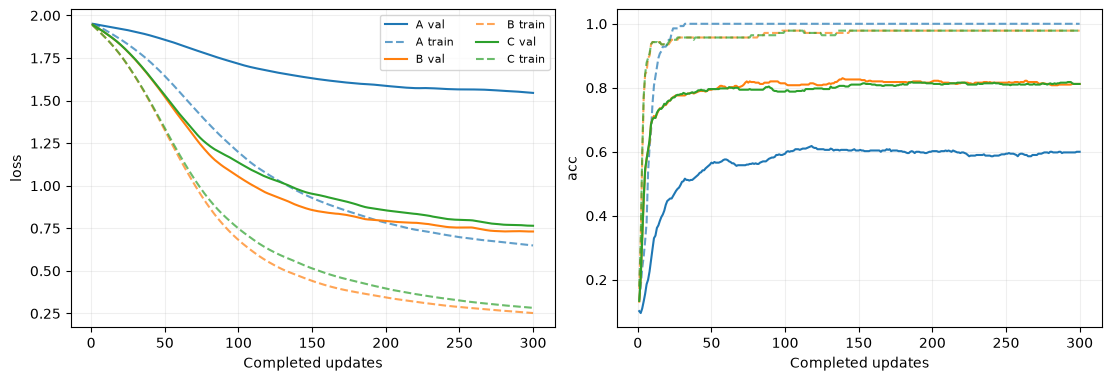

验证集选中的组别: B


In [8]:
runs = {}
for group in GROUPS:
    print(f"\n===== {group}: {GROUPS[group]} =====")
    model = make_model(group)
    group_edges = edges_for_group(group, edges, len(x))
    runs[group] = fit_model(
        model, x, group_edges, train_idx, y[train_idx], val_idx, y[val_idx],
        epochs=CONFIG["epochs"], lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"],
    )
print_comparison(runs)
fig = plot_history(runs)
plt.show()
# 按验证集冻结选择，不用测试结果决定采用哪组。
selected_group = max(runs, key=lambda g: (runs[g]["best_val_acc"], -runs[g]["best_val_loss"]))
print("验证集选中的组别:", selected_group)


**参考解释**

按表分别计算 B−A、C−B 的验证准确率差，用百分点表述。
    本实验回答给定划分、初始化与预算下的表现，不要求 C 必须超过 B。
    若两者接近，应结合参数、曲线、重复实验和耗时说明判断；不能只挑某个最有利的种子。
    固定划分的多个初始化只描述训练随机性，不代表跨划分稳定性。


## Q5 · 注意力观察与局部敏感性

用 C 的最佳验证模型。样本事先按验证索引和度数选取，不根据预测正确与否或权重形状筛选。
左图展示接收节点的全部一跳输入，线宽表示第一层多头平均权重，不画邻居之间的边；右图展示各头权重，包括自环。

颜色和类别名只使用训练／验证标签。测试邻居显示“?”，此阶段不读取其真实类别。
这些样本不是完整训练图；模型前向仍在完整图上进行。

观察：不同头是否相似？权重是否接近等权？有标签的同类邻居是否总得到更高权重？
不同接收节点的权重受邻域大小影响，不能直接用原始数值比较全图“重要性”。


固定验证样本（下标）: [11, 8, 15]
paper: 1128990 true: Genetic_Algorithms pred: Genetic_Algorithms


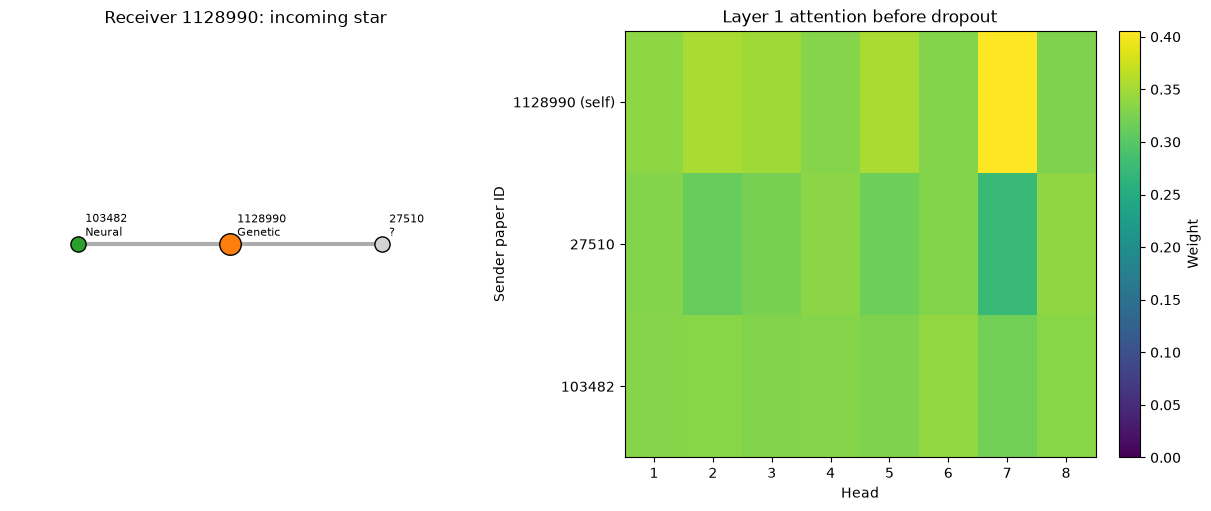

paper: 31349 true: Neural_Networks pred: Neural_Networks


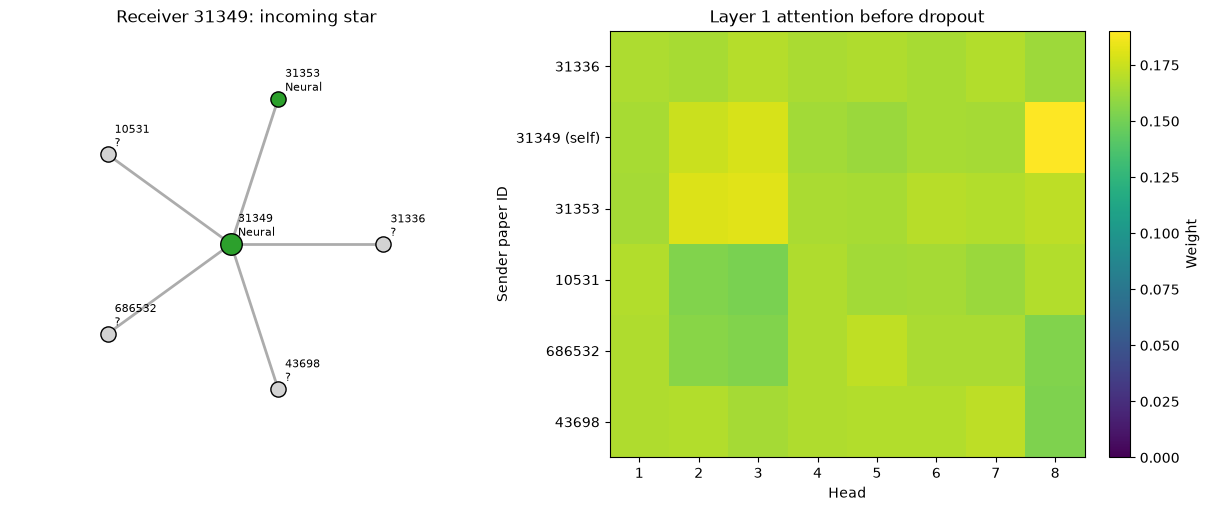

paper: 32083 true: Neural_Networks pred: Neural_Networks


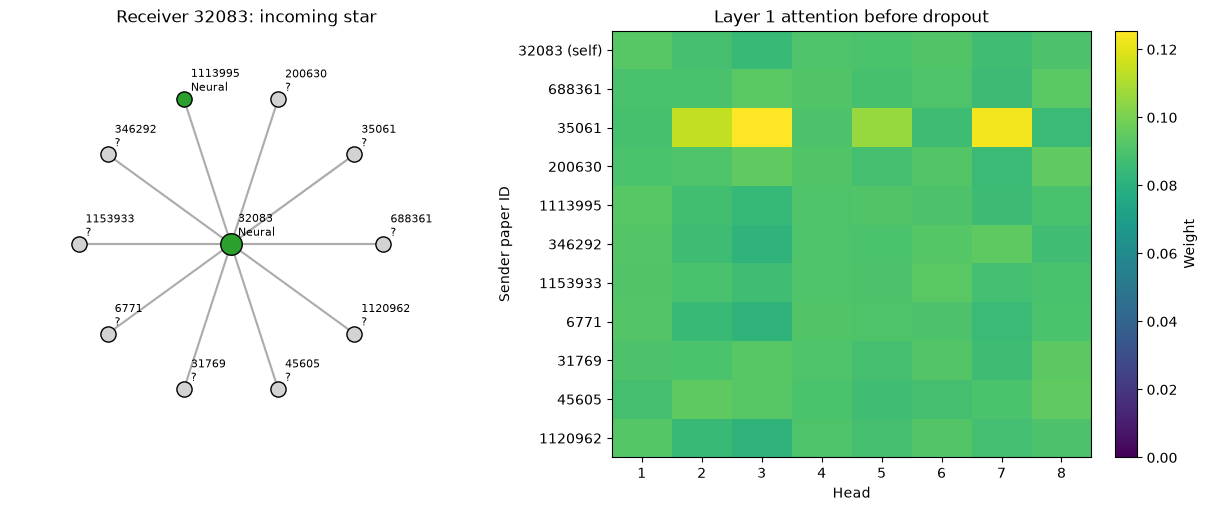

In [9]:
observed_nodes = select_validation_nodes(edges_cpu, val_idx)
known_indices = torch.cat([train_idx, val_idx]).tolist()
known_labels = {i: int(y[i]) for i in known_indices}
gat_model = runs["C"]["model"]
gat_model.eval()
with torch.no_grad():
    validation_logits, attention = gat_model(x, edges, return_attention=True)
print("固定验证样本（下标）:", observed_nodes)
for node in observed_nodes:
    print("paper:", paper_ids[node], "true:", class_names[known_labels[node]],
          "pred:", class_names[int(validation_logits[node].argmax())])
    fig = plot_attention_neighborhood(node, edges_cpu, attention[0], paper_ids, known_labels)
    plt.show()


接下来保持参数不变，分别移除第一层平均注意力最高和最低的一条外部关系，再重新前向。
无向关系要同时移除两个方向，自环保留；注意力随新邻域重新归一化。

先预测：移除高权重边，预测变化是否一定更大？最终分类是否一定改变？
关注正确类别分数和整个预测分布的变化，而不只看 argmax 是否翻转。


In [10]:
sensitivity_node = next(i for i in observed_nodes
                        if int((edges_cpu[0] == i).sum()) >= 3)
sensitivity = edge_sensitivity(gat_model, x, edges, sensitivity_node,
                               known_labels[sensitivity_node])
for row in sensitivity:
    print(row)
print("检查对象 paper:", paper_ids[sensitivity_node])


{'removed': 'highest', 'receiver': 11, 'sender': 659, 'layer1_mean_attention': 0.3311757743358612, 'prediction_before': 1, 'prediction_after': 1, 'true_class_prob_before': 0.27702784538269043, 'true_class_prob_after': 0.29750707745552063, 'probability_L1_change': 0.11511684954166412}
{'removed': 'lowest', 'receiver': 11, 'sender': 624, 'layer1_mean_attention': 0.3201062083244324, 'prediction_before': 1, 'prediction_after': 1, 'true_class_prob_before': 0.27702784538269043, 'true_class_prob_after': 0.36478787660598755, 'probability_L1_change': 0.25847330689430237}
检查对象 paper: 1128990


**参考解释**

注意力可帮助描述邻域内的权重分配，但它不是校准后的因果重要性。
    不同头可能相似，GAT 也可能学到接近等权的权重，这些结果都可以报告。
    边移除会改变归一化和两层传播路径，单条边的第一层权重不能完整预测最终输出变化。
    这里没有重新训练，结论是固定模型的局部敏感性；删边后重新训练研究的是另一问题。


## Q6 · 冻结方案，统一测试

完成训练／验证分析后，冻结配置、三组模型和所选轮次，再运行本节。
对三组预先规定的模型统一测试，报告准确率、Macro-F1、分类别召回率和混淆矩阵。
所选组别已由验证集确定，不能根据测试结果改选或继续搜索。

把下面的 FROZEN 改为 True，表示已完成上述步骤。参考版已冻结。
测试中没有预测出的类别，其 F1 按 0 计；Macro-F1 对七类等权平均。


A test accuracy: 0.5841 Macro-F1: 0.5759
  每类召回率: {'Case_Based': 0.661, 'Genetic_Algorithms': 0.753, 'Neural_Networks': 0.423, 'Probabilistic_Methods': 0.679, 'Reinforcement_Learning': 0.723, 'Rule_Learning': 0.628, 'Theory': 0.485}
B test accuracy: 0.8003 Macro-F1: 0.7848
  每类召回率: {'Case_Based': 0.817, 'Genetic_Algorithms': 0.953, 'Neural_Networks': 0.745, 'Probabilistic_Methods': 0.792, 'Reinforcement_Learning': 0.836, 'Rule_Learning': 0.829, 'Theory': 0.711}
C test accuracy: 0.7926 Macro-F1: 0.7787
  每类召回率: {'Case_Based': 0.795, 'Genetic_Algorithms': 0.953, 'Neural_Networks': 0.725, 'Probabilistic_Methods': 0.804, 'Reinforcement_Learning': 0.83, 'Rule_Learning': 0.822, 'Theory': 0.711}


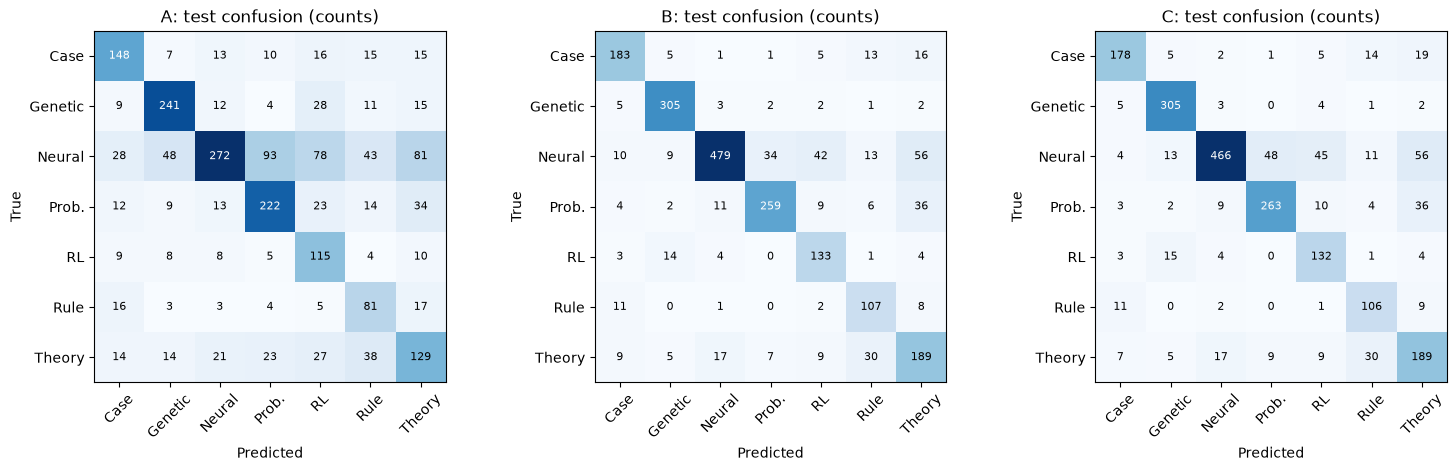

已保存划分、运行记录与验证集选定模型到: /Users/liyifan/USTC-AI-Notes/实验课/实验七/输出


In [11]:
FROZEN = True
assert FROZEN, "请先完成 Q4、Q5 并冻结配置，再统一进行最终测试。"
test_results = {}
for group, run in runs.items():
    model = run["model"].eval()
    with torch.no_grad():
        logits = model(x, edges_for_group(group, edges, len(x)))
    test_results[group] = classification_metrics(logits[test_idx.to(DEVICE)], y[test_idx])
    print(group, "test accuracy:", round(test_results[group]["accuracy"], 4),
          "Macro-F1:", round(test_results[group]["macro_f1"], 4))
    print("  每类召回率:", dict(zip(class_names, [round(v, 3) for v in test_results[group]["recall"]])))
fig = plot_confusions(test_results)
plt.show()
report = save_run_report(OUTPUT_DIR / "运行记录.json", runs, test_results,
                         CONFIG, ENVIRONMENT, split)
chosen = runs[selected_group]["model"]
torch.save({"state_dict": snapshot(chosen), "group": selected_group,
            "config": CONFIG, "classes": class_names,
            "preprocessing": "binary word features; row-normalized; undirected unique edges + self loops",
            "best_epoch": runs[selected_group]["best_epoch"]},
           OUTPUT_DIR / "验证集选定模型.pt")
print("已保存划分、运行记录与验证集选定模型到:", OUTPUT_DIR.resolve())


**实验结论与提交。** 在下面逐项填写，并保留代码输出：

1. **事实：** 用实际数值描述 A、B、C 的验证和测试结果，包括 B−A、C−B 的差值。
2. **解释：** 哪个假设得到支持？有哪些其他解释？邻居是否一定有帮助？
3. **证据边界：** 单次种子、固定划分、额外参数与注意力示例分别限制了什么结论？
4. **下一步：** 提出一项能区分解释的对照，说明固定什么、改变什么、如何评价。
5. **AI／排错记录：** 写下一条关键建议或假设，以及自己的核验方法和结果。

提交补全后的学生 notebook，保留输出，并附 lab_utils.py、数据和输出中的运行记录与划分索引。
模型文件可用于重建推理模型，不含优化器状态，不作为精确续训检查点。


**参考解释**

以表中实测结果填入结论，不用参考数值作为评分门槛。
    同类边较多是使用邻居信息的动机，不保证每个节点都受益；跨类别引用也可能提供有用信息。
    Macro-F1 与分类别召回率帮助检查总体准确率掩盖的问题。测试后提出的改进留给新的训练／验证实验。
    若报告多个种子，应报告全部预先规定的种子及均值与标准差，不挑最好的结果。


## 选做拓展 · 最多选择一项

- **标签数量：** 每类 5、10、20、40 个。开始实验前单独预留每类 40 个候选训练节点，固定其余验证和测试节点；训练集合逐级包含，未启用标签保持不可见。不可从已经查看成绩的主实验测试集补充训练标签。
- **关系缺失：** 按无向边随机移除部分引用，保留自环，再重新训练。固定每个比例的图，记录种子。与 Q5 的固定模型边移除区别开。
- **注意力头数：** 固定总隐藏维度 64，比较 1、2、4、8 头，相应改变每头维度，记录参数与耗时。
- **GCN 基线：** 使用教师确认的标准实现，说明其归一化与等权聚合版本的区别，在同一划分下比较。

拓展先写假设，用验证集作比较，冻结方案后统一测试。未运行的拓展不填入虚构结果。

## 参考材料

- [labml：在 Cora 上训练 GAT](https://nn.labml.ai/zh/graphs/gat/experiment.html)
- [labml：GAT 层](https://nn.labml.ai/zh/graphs/gat/index.html)
- [Cora 文件与 ID 映射参考](https://www.cnblogs.com/Catherinezhilin/p/16288734.html)
- [Graph Attention Networks](https://arxiv.org/abs/1710.10903)

课堂任务为自拟。采用独立测试集、按边计算和等权对照；本地 Cora 是七类，无孤立节点并不意味着整张图连通。


## 教师补充 · 本机预跑与结论示例

以下数值来自本目录实际运行记录，用于讨论，不作为评分门槛。
同一配置在不同环境可能有浮点或运行时间差异。

| 组别 | 最佳轮次 | 验证准确率 | 测试准确率 | 测试 Macro-F1 | 训练及逐轮评估耗时 |
| --- | ---: | ---: | ---: | ---: | ---: |
| A | 118 | 61.80% | 58.41% | 0.5759 | 3.4 秒 |
| B | 139 | 83.00% | 80.03% | 0.7848 | 4.0 秒 |
| C | 294 | 81.80% | 79.26% | 0.7787 | 5.9 秒 |

**事实示例：** 本次种子 42 下，测试准确率 B−A 为 +21.62 个百分点，C−B 为 -0.77 个百分点。验证集已在测试前选定 B。

**解释示例：** 该配置下邻居聚合明显改善了分类；本次结果没有支持学习注意力进一步改善准确率。这不说明注意力机制普遍无效，还可能与标签预算、归一化后的特征、正则或优化配置有关；要区分这些解释，需要新的训练／验证对照，不能继续用当前测试集搜索。

**局部分析示例：** 查看 Q5 实际输出，分别比较移除最高和最低权重关系后的概率变化。即使 argmax 未改变，分布仍可能明显变化；第一层的平均权重也不足以预测两层网络的全部响应。

三个预先规定的种子 42、2026、3407 使用同一划分与预算；标准差为样本标准差（ddof=1）。

| 组别 | 测试准确率均值 ± 标准差 | 测试 Macro-F1 均值 ± 标准差 |
| --- | ---: | ---: |
| A | 58.75% ± 0.30% | 0.5766 ± 0.0020 |
| B | 79.56% ± 0.48% | 0.7813 ± 0.0038 |
| C | 79.37% ± 0.10% | 0.7815 ± 0.0028 |

B、C 在这些重复中的表现接近。三次初始化不足以证明统计显著差异，也不足以证明两种方法等价；该记录仅描述固定划分上的训练随机性。
